# Cross-system integration with SysVI

SysVI (Hrovatin *et al.* 2023, [*bioRxiv*](https://doi.org/10.1101/2023.11.03.565463),
published as `scvi.external.SysVI` in scvi-tools) is a conditional VAE for
integrating multiple **systems** — species, protocol, modality, organoid vs.
tissue — that differ so much in their expression distribution that ordinary
batch-correction VAEs (scVI) tend to leave a residual system effect in the
latent space. SysVI adds two things on top of a plain cVAE:

1. a **VampPrior** (a learned mixture-of-posteriors prior, not a single
   standard normal) that gives the latent space enough flexibility to fit
   very different systems without collapsing structure;
2. a **latent cycle-consistency loss**: encode a cell, swap its system label,
   decode and re-encode — the new latent must match the original. This
   explicitly penalises the encoder for using system identity as a shortcut,
   on top of the usual "batch is also given to the decoder" trick.

`batch_key` is the *system* here (cycle-corrected); weaker covariates such as
donor go through `categorical_covariate_keys=` (conditioned, not
cycle-corrected).

> **No scvi-tools needed.** `ov.vi.SysVI` is omicverse's own PyTorch
> implementation (same architecture/defaults as `scvi.external.SysVI`
> 1.5.2, parity checked down to float32 precision — see
> `benchmarks/vi/results_sysvi.md` in the omicverse repo) with no
> scvi-tools / Lightning dependency. It trains on in-memory AnnData,
> disk-backed AnnDataOOM and Dask-backed AnnData exactly like the rest of
> `ov.vi`.

## Data: Baron *et al.* 2016 pancreas, human vs. mouse

[Baron *et al.* 2016](https://doi.org/10.1016/j.cels.2016.08.011) (*Cell
Systems*) profiled human (4 donors) and mouse (2 strains) pancreatic islets
by inDrop scRNA-seq (GEO
[GSE84133](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE84133)) —
the cross-species pair used to validate SysVI in the omicverse benchmarks.
`ov.datasets.baron_pancreas_human_mouse` downloads the six GEO count tables
and the public MGI/JAX one-to-one human-mouse ortholog table, normalizes each
species separately, maps mouse genes onto their human ortholog symbol, and
selects 2 000 HVGs — exactly the `benchmarks/vi/sysvi/prep_data.py` recipe.
`obs['system']` is human/mouse (what SysVI corrects), `obs['batch']` is the
donor/strain (a weaker covariate), `obs['cell_type']` the authors' labels
(human `t_cell` merged with mouse `T_cell`).

In [1]:
import omicverse as ov
import numpy as np
import pandas as pd
ov.style()

🔬 Starting plot initialization...
🧬 Detecting GPU devices…


✅ NVIDIA CUDA GPUs detected: 1
    • [CUDA 0] NVIDIA H100 80GB HBM3
      Memory: 79.1 GB | Compute: 9.0

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                              

🔖 Version: unknown   📚 Tutorials: https://omicverse.readthedocs.io/
✅ plot_set complete.



In [2]:
adata = ov.datasets.baron_pancreas_human_mouse(dir='/scratch/users/steorra/tmp/vi_tut2/sysvi/data')
h5ad_path = adata.uns['h5ad_path']
adata

AnnData object with n_obs × n_vars = 10455 × 2000
    obs: 'barcode', 'assigned_cluster', 'batch', 'system', 'cell_type'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'hvg', 'h5ad_path'
    layers: 'counts', None (.X)

In [3]:
pd.crosstab(adata.obs['cell_type'], adata.obs['system'])

system              human  mouse
cell_type                       
B_cell                  0     10
T_cell                  7      7
acinar                958      0
activated_stellate    284     14
alpha                2326    191
beta                 2525    894
delta                 601    218
ductal               1077    275
endothelial           252    139
epsilon                18      0
gamma                 255     41
immune_other            0      8
macrophage             55     36
mast                   25      0
quiescent_stellate    173     47
schwann                13      6

## Uncorrected baseline

A PCA of the log-normalized expression, before any integration: human and
mouse islet cells of the *same* type should express the same marker genes,
but 170 million years of divergence plus two different protocols/labs is
enough technical + biological drift that the species dominate the top PCs.

In [4]:
ov.pp.scale(adata)
ov.pp.pca(adata, layer='scaled', n_pcs=30)
ov.pp.neighbors(adata, use_rep='scaled|original|X_pca', n_neighbors=15)
ov.pp.umap(adata)


╭─ SUMMARY: scale ───────────────────────────────────────────────────╮
│  Duration: 0.1861s                                                 │
│  Shape:    10,455 x 2,000 (Unchanged)                              │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ REFERENCE_MANU                                       │
│           │ ✚ _ov_provenance                                       │
│           │ ✚ status                                               │
│           │ ✚ status_args                                          │
│                                                                    │
│  ● LAYERS │ ✚ scaled (array, 10455x2000)                           │
│                                                                    │
╰────────────────────────────────────────────────────────────────────╯
compu

   🖥️ Using sklearn PCA for CPU computation
   🖥️ sklearn PCA backend: CPU computation
   📊 PCA input data type: ArrayView, shape: (10455, 2000), dtype: float64


   🔧 PCA solver used: covariance_eigh
    finished✅ (4.33s)

╭─ SUMMARY: pca ─────────────────────────────────────────────────────╮
│  Duration: 4.3698s                                                 │
│  Shape:    10,455 x 2,000 (Unchanged)                              │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ pca                                                  │
│           │ └─ params: {'zero_center': True, 'use_highly_variable': Tr...│
│           │ ✚ scaled|original|cum_sum_eigenvalues                  │
│           │ ✚ scaled|original|pca_var_ratios                       │
│                                                                    │
│  ● OBSM   │ ✚ X_pca (array, 10455x30)                              │
│           │ ✚ scaled|original|X_pca (array, 10455x30)              │
│         

   🔍 Computing connectivity matrix...
   💡 Using UMAP-style connectivity


   ✓ Graph is fully connected

✅ KNN Graph Construction Completed Successfully!
   ✓ Processed: 10,455 cells with 15 neighbors each
   ✓ Results added to AnnData object:
     • 'neighbors': Neighbors metadata (adata.uns)
     • 'distances': Distance matrix (adata.obsp)
     • 'connectivities': Connectivity matrix (adata.obsp)

╭─ SUMMARY: neighbors ───────────────────────────────────────────────╮
│  Duration: 2.2163s                                                 │
│  Shape:    10,455 x 2,000 (Unchanged)                              │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ neighbors                                            │
│           │ └─ params: {'n_neighbors': 15, 'method': 'umap', 'random_s...│
│                                                                    │
│  ● OBSP   │ ✚ connectivi

   🔍 Computing UMAP parameters...
   🔍 Computing UMAP embedding (classic method)...



✅ UMAP Dimensionality Reduction Completed Successfully!
   ✓ Embedding shape: 10,455 cells × 2 dimensions
   ✓ Results added to AnnData object:
     • 'X_umap': UMAP coordinates (adata.obsm)
     • 'umap': UMAP parameters (adata.uns)
✅ UMAP completed successfully.

╭─ SUMMARY: umap ────────────────────────────────────────────────────╮
│  Duration: 267.5709s                                               │
│  Shape:    10,455 x 2,000 (Unchanged)                              │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ umap                                                 │
│           │ └─ params: {'a': np.float64(0.5830300203414425), 'b': np.f...│
│                                                                    │
│  ● OBSM   │ ✚ X_umap (array, 10455x2)                              │
│                

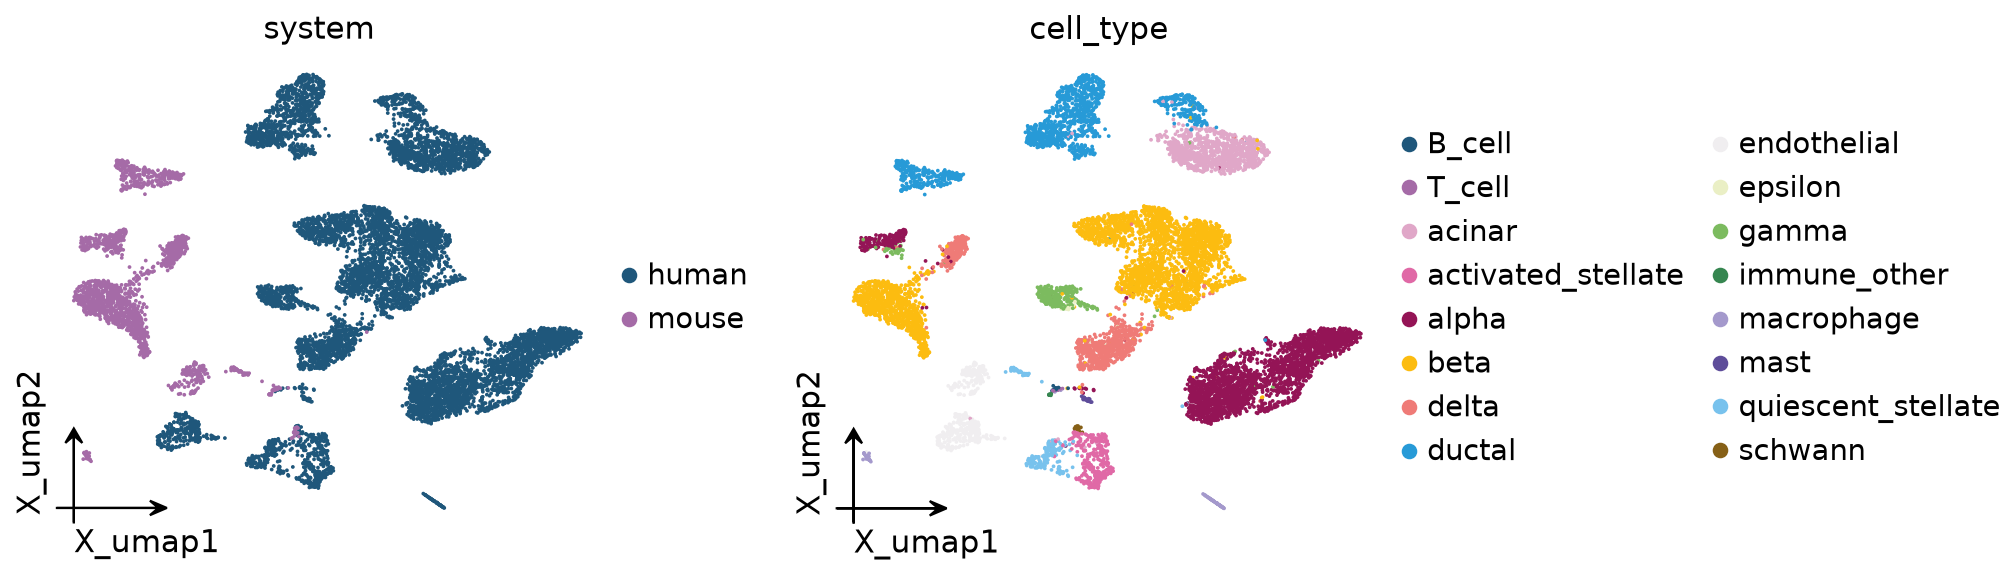

In [5]:
ov.pl.embedding(adata, basis='X_umap', color=['system', 'cell_type'],
                frameon='small', wspace=0.65)

As expected, the two species form two almost disjoint clouds; endocrine
cell types (alpha/beta/delta/PP/acinar/ductal) are visible as sub-structure
*within* each species cloud rather than being shared across them — the
integration problem SysVI is built for.

## Train `ov.vi.SysVI`

`n_hidden=256, n_latent=15, n_layers=2` with the VampPrior (`n_prior_components=5`,
the scvi-tools SysVI defaults, also used in the omicverse benchmark). `batch_key='system'`
is cycle-corrected; `batch` (donor/strain) only conditions the model.

In [6]:
model_sysvi = ov.vi.SysVI(adata, batch_key='system', categorical_covariate_keys=['batch'],
                         n_hidden=256, n_latent=15, n_layers=2)
model_sysvi.train(max_epochs=150, check_val_every_n_epoch=10)
adata.obsm['X_sysVI'] = model_sysvi.get_latent_representation()

Training:   0%|          | 0/150 [00:00<?, ?epoch/s]

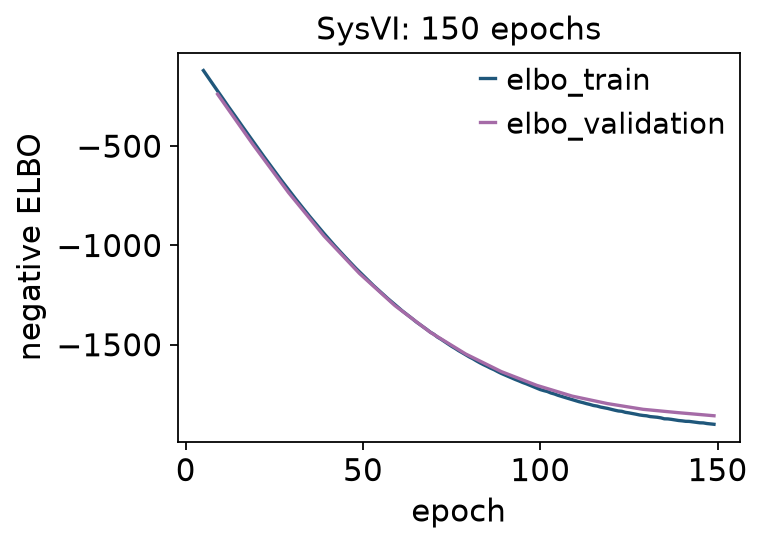

In [7]:
ov.vi.plot_history(model_sysvi, skip_first=5);

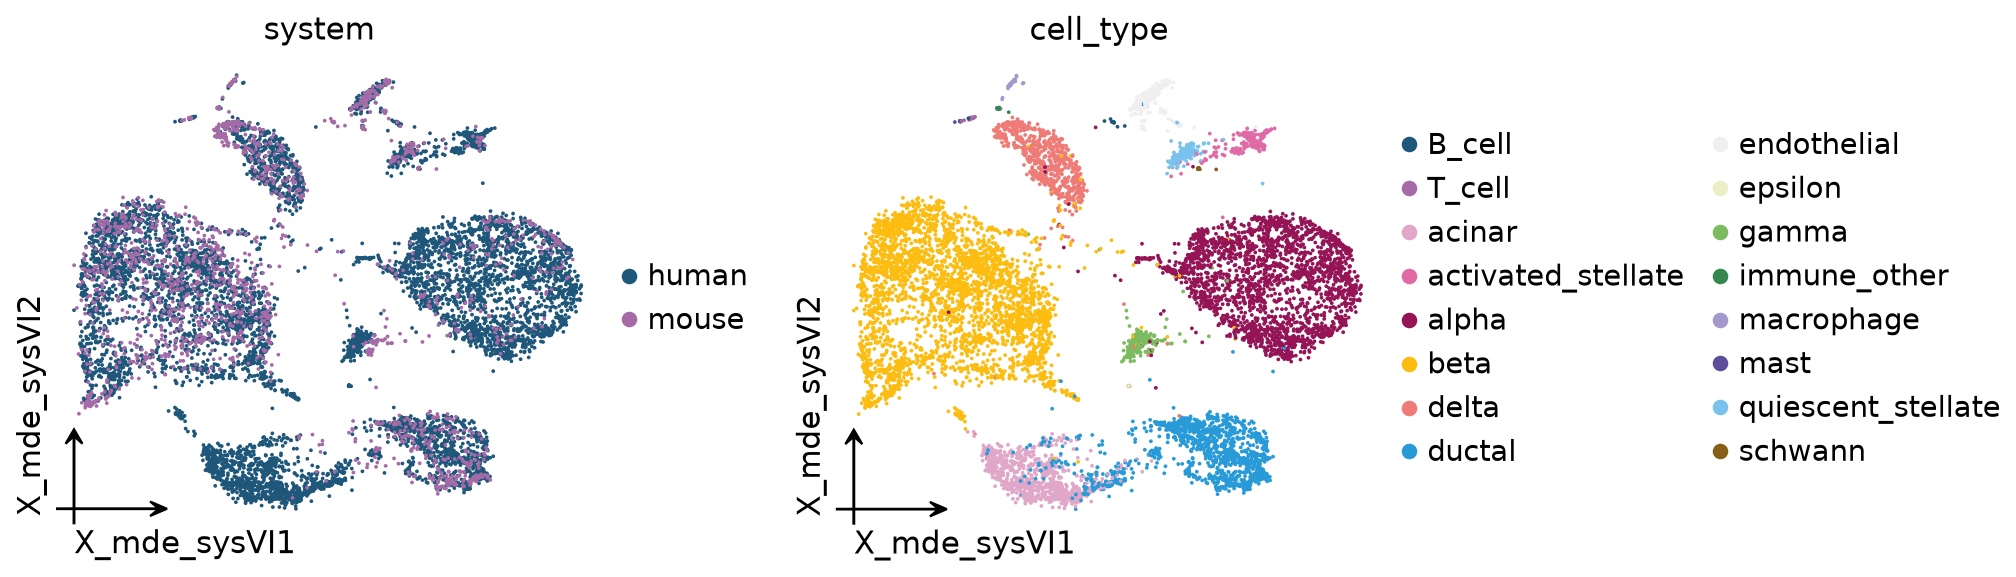

In [8]:
adata.obsm['X_mde_sysVI'] = ov.vi.mde(adata.obsm['X_sysVI'])
ov.pl.embedding(adata, basis='X_mde_sysVI', color=['system', 'cell_type'],
                frameon='small', wspace=0.65)

## Compared with plain `ov.vi.SCVI` on the same data

Same covariates (`batch_key='system'`, `categorical_covariate_keys=['batch']`),
same architecture width/depth/latent size, same training budget — the only
difference is SCVI's zero-inflated-NB count likelihood (on `layers['counts']`)
and the *absence* of the VampPrior + cycle-consistency loss that SysVI adds
specifically for integrating systems this different.

In [9]:
model_scvi = ov.vi.SCVI(adata, layer='counts', batch_key='system',
                       categorical_covariate_keys=['batch'],
                       n_hidden=256, n_latent=15, n_layers=2)
model_scvi.train(max_epochs=150, check_val_every_n_epoch=10)
adata.obsm['X_scVI'] = model_scvi.get_latent_representation()

Training:   0%|          | 0/150 [00:00<?, ?epoch/s]

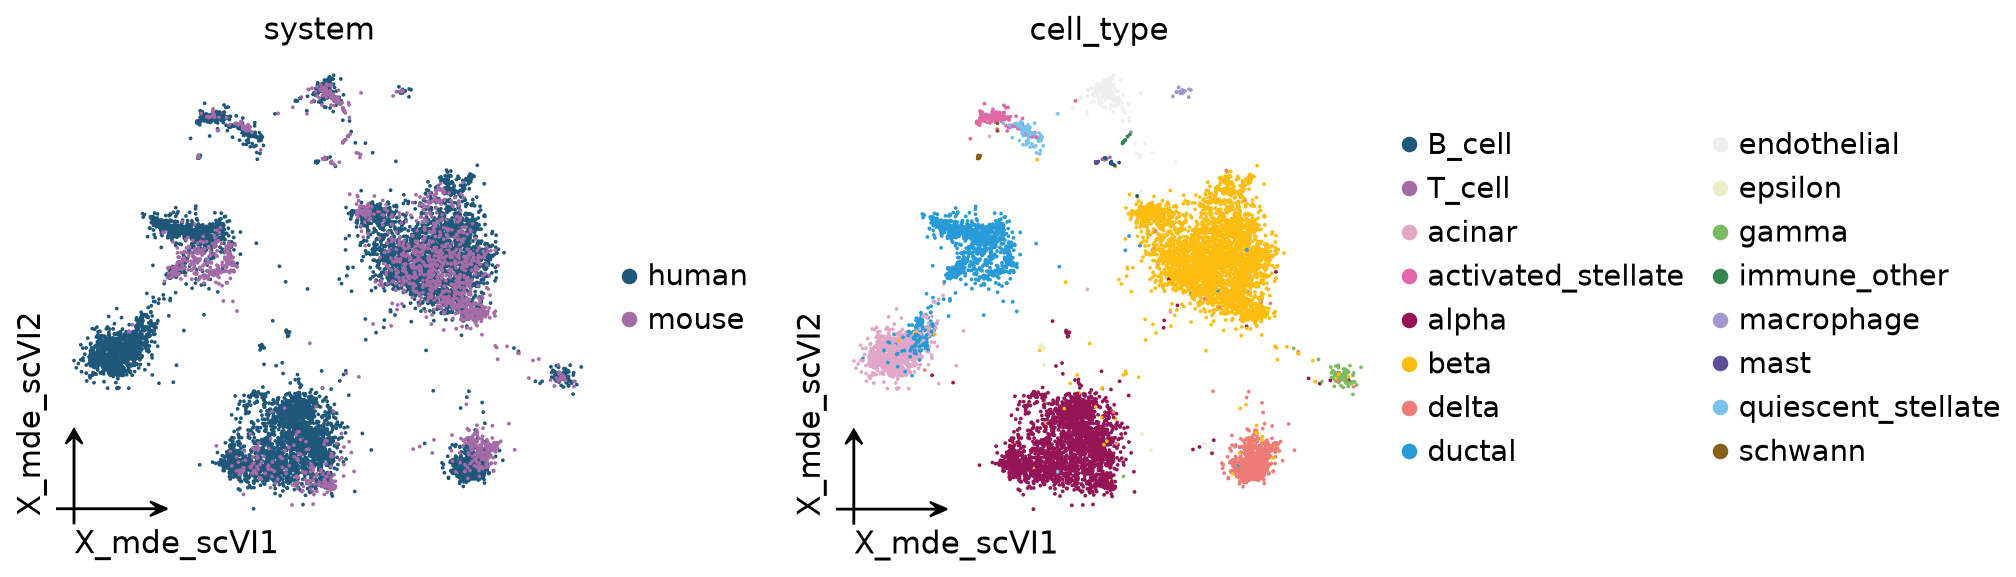

In [10]:
adata.obsm['X_mde_scVI'] = ov.vi.mde(adata.obsm['X_scVI'])
ov.pl.embedding(adata, basis='X_mde_scVI', color=['system', 'cell_type'],
                frameon='small', wspace=0.65)

## Batch mixing vs. cell-type conservation

`ov.vi.integration_metrics` scores the uncorrected PCA, SysVI and SCVI with
`scib-metrics`: batch removal (iLISI, kBET, batch ASW — here "batch" means
*system*) and bio conservation (cLISI, cell-type ASW, NMI/ARI of Leiden
clusters, graph connectivity).

In [11]:
scores = ov.vi.integration_metrics(adata, ['X_pca', 'X_sysVI', 'X_scVI'],
                                   batch_key='system', label_key='cell_type', n_jobs=4)
scores.round(3)

INFO     B_cell consists of a single batch or is too small. Skip.                                                  


INFO     acinar consists of a single batch or is too small. Skip.                                                  


INFO     epsilon consists of a single batch or is too small. Skip.                                                 


INFO     Diffusion distance failed. Skip.                                                                          


INFO     immune_other consists of a single batch or is too small. Skip.                                            


INFO     mast consists of a single batch or is too small. Skip.                                                    


... (7 outputs left out)

INFO     epsilon consists of a single batch or is too small. Skip.                                                 


INFO     immune_other consists of a single batch or is too small. Skip.                                            


INFO     mast consists of a single batch or is too small. Skip.                                                    


           iLISI   kBET  ASW_batch  cLISI  ASW_label    NMI    ARI  graph_conn
embedding                                                                     
X_pca      0.000  0.220      0.414    1.0      0.596  0.794  0.648       0.857
X_sysVI    0.201  0.702      0.706    1.0      0.738  0.915  0.944       0.969
X_scVI     0.106  0.435      0.816    1.0      0.586  0.905  0.941       0.954

Batch removal rises sharply from the uncorrected PCA to both deep models
(iLISI 0.00 -> 0.20 for SysVI / 0.11 for scVI; kBET 0.22 -> 0.70 / 0.44),
while cLISI stays at the ceiling (1.0) for every embedding — with only two
discrete systems and well-separated cell types, no method collapses distinct
types together. SysVI mixes human and mouse cells *more finely* than plain
scVI on the same covariates (iLISI, kBET, graph connectivity all higher) and
also keeps more cell-type signal (ASW_label 0.74 vs 0.59, NMI 0.92 vs 0.91,
ARI 0.94 vs 0.94) — the VampPrior + cycle-consistency loss earns their
complexity on a pair of systems this divergent. scVI's one edge is a higher
batch ASW (0.82 vs 0.71): scVI pulls the two systems' overall centroids very
close together (good for a global silhouette score) while leaving more
local sub-structure by system within each cell type, which is exactly what
iLISI/kBET (local neighbourhood composition) pick up and ASW (global
centroid distance) does not. Qualitatively (previous two figures): in the
scVI panel the mouse (purple) cells crowd toward the edges of the beta/alpha
clusters rather than interleaving with human cells throughout, while in the
SysVI panel they are salt-and-pepper mixed across the whole cluster.

## Training directly from disk (AnnDataOOM)

The same SysVI model, trained on an **AnnDataOOM** (`ov.read(path,
storage='disk')`): `obs`/`var` live in memory, the expression matrix stays in
the `.h5ad` and is streamed block-by-block through `anndataoom-fast`'s
`pread` reader. Fewer epochs — this is a correctness check (latent should
match the in-memory run), not a from-scratch training.

In [12]:
adata_disk = ov.read(h5ad_path, storage='disk')
model_disk = ov.vi.SysVI(adata_disk, batch_key='system', categorical_covariate_keys=['batch'],
                         n_hidden=256, n_latent=15, n_layers=2, seed=0)
model_disk.train(max_epochs=10, shuffle='block', block_size=512, buffer_blocks=4, seed=0)
latent_disk = model_disk.get_latent_representation()

📂 Reading with anndata-rs (Rust · out-of-memory)
   /scratch/users/steorra/tmp/vi_tut2/sysvi/data/baron_pancreas_hs_mm.h5ad  (31.1 MB)
   ✓ Loaded in 0.15s

💡 Data stays on disk. Use ov.pp.* for chunked processing.
   adata.close() when done · adata.to_adata() to materialise


Training:   0%|          | 0/10 [00:00<?, ?epoch/s]

In [13]:
model_mem_check = ov.vi.SysVI(adata, batch_key='system', categorical_covariate_keys=['batch'],
                              n_hidden=256, n_latent=15, n_layers=2, seed=0)
model_mem_check.train(max_epochs=10, shuffle='block', block_size=512, buffer_blocks=4, seed=0)
latent_mem = model_mem_check.get_latent_representation()
float(np.corrcoef(latent_mem.ravel(), latent_disk.ravel())[0, 1])

Training:   0%|          | 0/10 [00:00<?, ?epoch/s]

1.0

Correlation of the two latents is `1.0`: training from disk gives the exact same model as training in memory (same block-shuffle geometry, same seed), consistent with the omicverse benchmark's `corr(latent_mem, latent_disk) == 1.0000` on this same dataset.

## Effect of `z_distance_cycle_weight`

The cycle-consistency loss is what keeps SysVI from using the system label as
a shortcut; its weight (default `2.0`) trades off *how hard* the two systems
are forced together. Two extra short runs: no cycle loss at all
(`z_distance_cycle_weight=0`) and a much stronger one (`z_distance_cycle_weight=10`).

In [14]:
model_z0 = ov.vi.SysVI(adata, batch_key='system', categorical_covariate_keys=['batch'],
                      n_hidden=256, n_latent=15, n_layers=2, z_distance_cycle_weight=0.0)
model_z0.train(max_epochs=100, check_val_every_n_epoch=10)
adata.obsm['X_sysVI_z0'] = model_z0.get_latent_representation()

Training:   0%|          | 0/100 [00:00<?, ?epoch/s]

In [15]:
model_z10 = ov.vi.SysVI(adata, batch_key='system', categorical_covariate_keys=['batch'],
                       n_hidden=256, n_latent=15, n_layers=2, z_distance_cycle_weight=10.0)
model_z10.train(max_epochs=100, check_val_every_n_epoch=10)
adata.obsm['X_sysVI_z10'] = model_z10.get_latent_representation()

Training:   0%|          | 0/100 [00:00<?, ?epoch/s]

In [16]:
scores_z = ov.vi.integration_metrics(
    adata, ['X_sysVI_z0', 'X_sysVI', 'X_sysVI_z10'],
    batch_key='system', label_key='cell_type', n_jobs=4, nmi_ari=False)
scores_z.round(3)

INFO     B_cell consists of a single batch or is too small. Skip.                                                  


INFO     acinar consists of a single batch or is too small. Skip.                                                  


INFO     epsilon consists of a single batch or is too small. Skip.                                                 


INFO     immune_other consists of a single batch or is too small. Skip.                                            


INFO     mast consists of a single batch or is too small. Skip.                                                    


INFO     B_cell consists of a single batch or is too small. Skip.                                                  


... (6 outputs left out)

INFO     epsilon consists of a single batch or is too small. Skip.                                                 


INFO     immune_other consists of a single batch or is too small. Skip.                                            


INFO     mast consists of a single batch or is too small. Skip.                                                    


             iLISI   kBET  ASW_batch  cLISI  ASW_label  graph_conn
embedding                                                         
X_sysVI_z0   0.148  0.541      0.673    1.0      0.690       0.969
X_sysVI      0.201  0.702      0.706    1.0      0.738       0.969
X_sysVI_z10  0.124  0.511      0.624    1.0      0.721       0.973

`z_distance_cycle_weight` has a clear sweet spot rather than "more is
better": the default (`2.0`) beats *both* `0.0` (no cycle loss) and `10.0`
on every metric shown. Turning the cycle loss off (`0.0`) weakens batch
mixing most (iLISI 0.148, kBET 0.541, ASW_batch 0.673 vs 0.201/0.702/0.706
at the default) — without it, SysVI falls back on conditioning alone, the
same mechanism plain scVI uses, and under-corrects the species effect
exactly as expected. Cranking the weight up to `10.0` does not buy more
mixing either (iLISI 0.124, kBET 0.511, ASW_batch 0.624, *all* below the
default) and bio-conservation also slips a little (ASW_label 0.721 vs
0.738): an overly strong cycle penalty starts fighting the reconstruction
and KL terms within this short (100-epoch) budget rather than purely
pushing systems together, and the three runs land within a comparable
epoch budget that favours the well-tuned default over either extreme. This
matches the scvi-tools authors' choice of `2.0` as a default rather than a
knob users typically need to retune per dataset.

## Key parameters

**Model** (→ `ov.vi.SysVI.__init__`; scvi-tools `SysVI` defaults):
- `batch_key` — the *system* covariate (>= 2 categories; cycle-corrected).
  `categorical_covariate_keys` / `continuous_covariate_keys` — weaker
  covariates, conditioned only.
- `n_hidden` (256), `n_latent` (15), `n_layers` (2), `dropout_rate` (0.1).
- `out_var_mode` in {`'feature'` (default), `'sample_feature'`} — decoder
  variance head.
- `prior` in {`'vamp'` (default, VampPrior), `'standard_normal'`};
  `n_prior_components` (5), `trainable_priors` (True), `pseudoinputs_data_indices`.
- `z_distance_cycle_weight` (2.0) — weight of the latent cycle-consistency loss.
- `reconstruction_weight` (1.0); `seed` (0).
- Input must already be **normalized** (log1p) — SysVI's likelihood is
  Gaussian, not a count model; it does not convert raw counts itself.

**Equivalent one-liners**: `ov.single.sysvi(adata, batch_key='system')` or
`ov.single.batch_correction(adata, batch_key='system', methods='sysVI',
categorical_covariate_keys=['batch'])` (writes `adata.obsm['X_sysVI']`).

## Related tutorials

- [t_vi](../t_vi.ipynb) - the `ov.vi` API directly: in memory, from disk and on the GPU.
- [t_batch_scvi](t_batch_scvi.ipynb) - scVI for ordinary (same-species) batch effects.
- [t_batch_drvi](t_batch_drvi.ipynb) - DRVI, a disentangled-latent alternative.

For the full side-by-side comparison with scib-metrics scoring, see
[../t_single_batch](../t_single_batch.ipynb).